# Projeto Prático 2.1 — Perceptron de Rosenblatt

**Disciplina:** Redes Neurais Artificiais
**Equipe:** Rennan Kauê de Oliveira Silva e Danilo Fernandes Cavalcante

Este notebook implementa o treinamento supervisionado do Perceptron de Rosenblatt usando NumPy em todas as operações matriciais. Ele cobre as três partes do projeto: (I) um problema linearmente separável, (II) a experimentação com seis configurações de taxa de aprendizado e de intervalo de pesos iniciais e (III) a validação holdout em um problema não linearmente separável.

## Plano de execução

1. Carregar e validar os arrays fornecidos.
2. Implementar e executar o Perceptron até a convergência para `dataAll20262.txt` (Parte I).
3. Executar os seis cenários, com dez repetições cada, para o arquivo definido pelo identificador da dupla (Parte II), com os atributos normalizados.
4. Separar `dataHoldout20262.txt` em treino/teste, treinar por 100 épocas e avaliar as métricas (Parte III).

## Bibliotecas e funções auxiliares

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DADOS = Path('dados')
CORES = np.array(['tab:red', 'tab:blue'])

def carregar_dados(nome_arquivo):
    """Carrega os exemplos e os normaliza para a forma (m, 3): x1, x2, yd."""
    dados = np.load(DADOS / nome_arquivo)
    dados = dados.reshape(-1, 3)
    X = dados[:, :2].astype(float)
    y = dados[:, 2].astype(int)
    if not np.all(np.isin(y, [0, 1])):
        raise ValueError('Os rótulos devem pertencer a {0, 1}.')
    return X, y

def normalizar(X, escala=None):
    """Divide cada atributo pelo seu maior valor absoluto, levando-o a [-1, 1]."""
    if escala is None:
        escala = np.abs(X).max(axis=0)
    return X / escala, escala

def pesos_escala_original(pesos, escala):
    """Converte pesos treinados em X/escala para o espaço original dos atributos."""
    return np.concatenate(([pesos[0]], pesos[1:] / escala))

def degrau(u):
    return (u >= 0).astype(int)

def treinar_perceptron(X, y, taxa_aprendizado=0.1, intervalo=(-0.5, 0.5),
                       max_epocas=None, embaralhar=False, gerador=None, parar_na_convergencia=True):
    """Treina o Perceptron e retorna pesos, ajustes, épocas e histórico de erros."""
    if gerador is None:
        gerador = np.random.default_rng()

    X_com_bias = np.column_stack((np.ones(X.shape[0]), X))
    pesos = gerador.uniform(intervalo[0], intervalo[1], size=X_com_bias.shape[1])
    pesos_iniciais = pesos.copy()
    ajustes = 0
    historico_erros = []
    epoca = 0

    while max_epocas is None or epoca < max_epocas:
        indices = gerador.permutation(X.shape[0]) if embaralhar else np.arange(X.shape[0])
        erros = 0
        for i in indices:
            previsto = int(X_com_bias[i] @ pesos >= 0)
            erro = y[i] - previsto
            if erro != 0:
                pesos += taxa_aprendizado * erro * X_com_bias[i]
                ajustes += 1
                erros += 1
        historico_erros.append(erros)
        epoca += 1
        if erros == 0 and parar_na_convergencia:
            break

    return {
        'pesos': pesos, 'pesos_iniciais': pesos_iniciais, 'ajustes': ajustes,
        'epocas': epoca, 'historico_erros': historico_erros
    }

def prever(X, pesos):
    X_com_bias = np.column_stack((np.ones(X.shape[0]), X))
    return degrau(X_com_bias @ pesos)

def plotar_dados_e_reta(X, y, pesos, ax, titulo):
    ax.scatter(X[:, 0], X[:, 1], c=CORES[y], alpha=0.7, edgecolors='none', label=None)
    limites_x = np.array([X[:, 0].min(), X[:, 0].max()])
    if not np.isclose(pesos[2], 0):
        limites_y = -(pesos[0] + pesos[1] * limites_x) / pesos[2]
        ax.plot(limites_x, limites_y, color='black', linewidth=2, label='Reta de separação')
    else:
        ax.axvline(-pesos[0] / pesos[1], color='black', linewidth=2, label='Reta de separação')
    margem = 0.05 * (X[:, 1].max() - X[:, 1].min())
    ax.set_ylim(X[:, 1].min() - margem, X[:, 1].max() + margem)
    ax.scatter([], [], color='tab:red', label='Classe 0')
    ax.scatter([], [], color='tab:blue', label='Classe 1')
    ax.set(title=titulo, xlabel='$x_1$', ylabel='$x_2$')
    ax.legend()
    ax.grid(alpha=0.25)


## Parte I — problema linearmente separável

Configuração exigida: função degrau com limiar 0, taxa de aprendizado $\eta=0,1$ e pesos iniciais em $U(-0,5; +0,5)$. O treinamento só termina quando uma época inteira não tem erros.

Formato de X: (1000, 2)
Distribuição das classes: 0 = 500, 1 = 500
Vetor inicial de pesos [bias, w1, w2]: [-0.41780297 -0.16210423 -0.08951983]
Vetor final de pesos   [bias, w1, w2]: [-3.17802968e-01  8.63060483e+01 -4.26048395e+02]
Total de ajustes: 65
Épocas até a convergência: 4
Erros na última época: 0
Acurácia no conjunto de treinamento: 100.00%


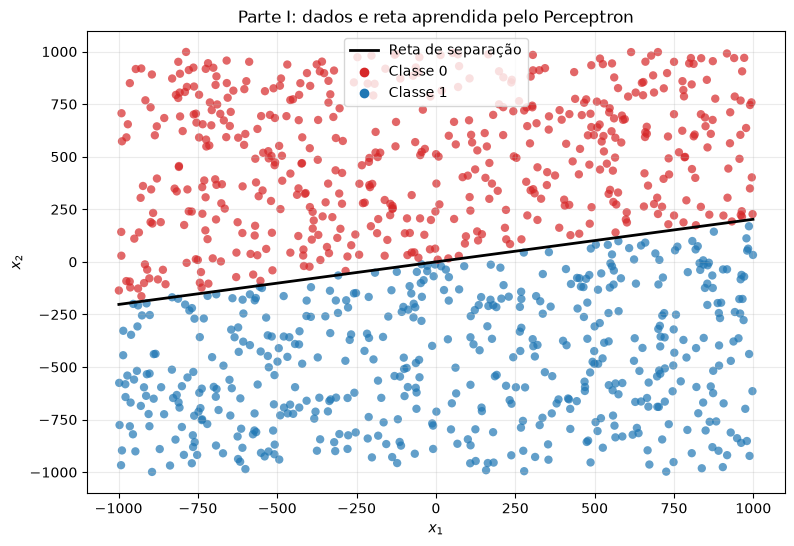

In [2]:
X_all, y_all = carregar_dados('dataAll20262.txt')
print(f'Formato de X: {X_all.shape}')
print(f'Distribuição das classes: 0 = {(y_all == 0).sum()}, 1 = {(y_all == 1).sum()}')

resultado_parte_i = treinar_perceptron(
    X_all, y_all, taxa_aprendizado=0.1, intervalo=(-0.5, 0.5)
)

print('Vetor inicial de pesos [bias, w1, w2]:', resultado_parte_i['pesos_iniciais'])
print('Vetor final de pesos   [bias, w1, w2]:', resultado_parte_i['pesos'])
print('Total de ajustes:', resultado_parte_i['ajustes'])
print('Épocas até a convergência:', resultado_parte_i['epocas'])
print('Erros na última época:', resultado_parte_i['historico_erros'][-1])
print('Acurácia no conjunto de treinamento:',
      f"{(prever(X_all, resultado_parte_i['pesos']) == y_all).mean():.2%}")

fig, ax = plt.subplots(figsize=(9, 6))
plotar_dados_e_reta(X_all, y_all, resultado_parte_i['pesos'], ax,
                     'Parte I: dados e reta aprendida pelo Perceptron')
plt.show()


## Parte II — experimentação

Como os últimos dígitos das matrículas são 6 e 6, o identificador da dupla é $(6 + 6) \bmod 4 = 0$. Portanto, esta parte usa `data020262.txt`. Cada configuração é repetida 10 vezes.

### Por que normalizar os atributos

Nesse arquivo, $x_1$ e $x_2$ variam em $[-1000, 1000]$, enquanto a entrada do bias vale 1. A cada ajuste, os pesos de $x_1$ e $x_2$ podem mudar até $1000\,\eta$, mas o bias muda só $\eta$. Como o conjunto é linearmente separável com margem muito pequena, o neurônio passa a oscilar em torno da solução e demora demais para convergir. A célula abaixo mostra isso: com os dados brutos e $\eta = 0{,}1$, ainda há erros após 2.000 épocas.

Por isso, cada atributo é dividido pelo seu maior valor absoluto, ficando em $[-1, 1]$. A normalização é uma mudança de escala linear, recomendada na literatura para o Perceptron: ela não altera a separabilidade das classes nem o algoritmo de treinamento, que continua sendo a regra de Rosenblatt.

In [3]:
IDENTIFICADOR_EQUIPE = 0
X_exp_bruto, y_exp = carregar_dados(f'data{IDENTIFICADOR_EQUIPE}20262.txt')

teste_bruto = treinar_perceptron(X_exp_bruto, y_exp, taxa_aprendizado=0.1, intervalo=(-0.5, 0.5),
                                 max_epocas=2000, gerador=np.random.default_rng(0))
print('Dados brutos — épocas executadas:', teste_bruto['epocas'])
print('Erros nas últimas 5 épocas:', teste_bruto['historico_erros'][-5:])

Dados brutos — épocas executadas: 2000
Erros nas últimas 5 épocas: [49, 48, 48, 48, 45]


In [4]:
from prettytable import PrettyTable

X_exp, escala_exp = normalizar(X_exp_bruto)
configuracoes = [
    (taxa, intervalo)
    for taxa in (0.4, 0.1, 0.01)
    for intervalo in ((-100, 100), (-0.5, 0.5))
]

resumos_experimentos = []
ajustes_por_configuracao = []
epocas_por_configuracao = []
for indice_configuracao, (taxa, intervalo) in enumerate(configuracoes):
    execucoes = []
    for repeticao in range(10):
        gerador = np.random.default_rng(1000 * indice_configuracao + repeticao)
        execucoes.append(treinar_perceptron(
            X_exp, y_exp, taxa_aprendizado=taxa, intervalo=intervalo, gerador=gerador
        ))
    ajustes = np.array([execucao['ajustes'] for execucao in execucoes])
    epocas = np.array([execucao['epocas'] for execucao in execucoes])
    ajustes_por_configuracao.append(ajustes)
    epocas_por_configuracao.append(epocas)
    resumos_experimentos.append({
        'taxa': taxa, 'intervalo': intervalo, 'media_ajustes': ajustes.mean(),
        'desvio_ajustes': ajustes.std(ddof=1), 'min_epocas': epocas.min(),
        'max_epocas': epocas.max()
    })

tabela = PrettyTable()
tabela.field_names = ['Taxa de aprendizado', 'Intervalo de pesos', 'Qtde. ajustes',
                      'Min. épocas', 'Max. épocas']
for resumo in resumos_experimentos:
    tabela.add_row([
        f"η = {resumo['taxa']}", str(resumo['intervalo']),
        f"{resumo['media_ajustes']:.2f} ± {resumo['desvio_ajustes']:.2f}",
        resumo['min_epocas'], resumo['max_epocas']
    ])
print(tabela)

+---------------------+--------------------+-------------------+-------------+-------------+
| Taxa de aprendizado | Intervalo de pesos |   Qtde. ajustes   | Min. épocas | Max. épocas |
+---------------------+--------------------+-------------------+-------------+-------------+
|       η = 0.4       |    (-100, 100)     |  722.00 ± 556.64  |      8      |     278     |
|       η = 0.4       |    (-0.5, 0.5)     |  617.60 ± 460.83  |      8      |     146     |
|       η = 0.1       |    (-100, 100)     |  1431.50 ± 702.73 |      6      |     434     |
|       η = 0.1       |    (-0.5, 0.5)     |  1045.30 ± 585.53 |      18     |     341     |
|       η = 0.01      |    (-100, 100)     | 8827.90 ± 5418.97 |      22     |     256     |
|       η = 0.01      |    (-0.5, 0.5)     |  549.30 ± 595.97  |      2      |     439     |
+---------------------+--------------------+-------------------+-------------+-------------+


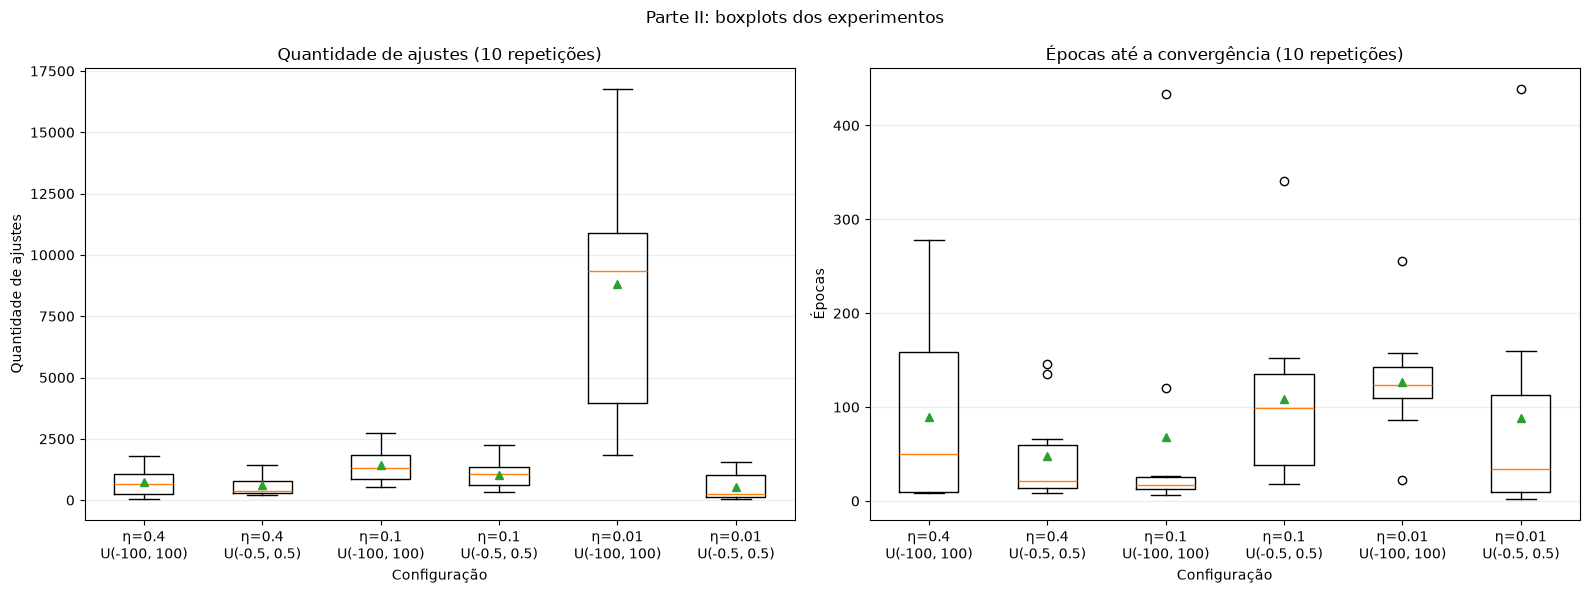

In [5]:
rotulos = [f"η={taxa}\nU{intervalo}" for taxa, intervalo in configuracoes]
fig, eixos = plt.subplots(1, 2, figsize=(16, 6))
eixos[0].boxplot(ajustes_por_configuracao, tick_labels=rotulos, showmeans=True)
eixos[0].set(title='Quantidade de ajustes (10 repetições)', xlabel='Configuração',
             ylabel='Quantidade de ajustes')
eixos[1].boxplot(epocas_por_configuracao, tick_labels=rotulos, showmeans=True)
eixos[1].set(title='Épocas até a convergência (10 repetições)', xlabel='Configuração',
             ylabel='Épocas')
for ax in eixos:
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Parte II: boxplots dos experimentos')
plt.tight_layout()
plt.show()

### Análise dos boxplots

**Quantidade de ajustes.** A configuração $\eta = 0{,}01$ com pesos em $U(-100; +100)$ é claramente a pior: em média foram 8.827,90 ± 5.418,97 ajustes, e mesmo o seu menor valor (≈ 1.800) fica acima da mediana de todas as outras configurações. As outras cinco têm caixas muito sobrepostas e desvios padrão da mesma ordem das médias (por exemplo, 617,60 ± 460,83 para $\eta = 0{,}4$, $U(-0{,}5; +0{,}5)$, e 549,30 ± 595,97 para $\eta = 0{,}01$, $U(-0{,}5; +0{,}5)$). Com apenas 10 repetições, não dá para apontar uma delas como a melhor. O máximo que se observa é uma tendência: as três com pesos iniciais pequenos ficaram com médias menores do que as respectivas versões com $U(-100; +100)$.

**Épocas até a convergência.** Aqui não há diferença clara: as caixas de todas as configurações se sobrepõem, e todas têm repetições que convergem rápido (2 a 22 épocas) e outras que levam centenas de épocas (146 a 439). O número de épocas depende mais do sorteio dos pesos iniciais do que da configuração.

**Explicação.** Pela regra de Rosenblatt, $\mathbf{w}(t) = \mathbf{w}(0) + \eta \sum e_k \mathbf{x}_k$. Dividindo tudo por $\eta$, a sequência de decisões do neurônio depende só da razão $\mathbf{w}(0)/\eta$: quanto maiores os pesos iniciais em relação à taxa de aprendizado, mais ajustes são necessários para "desfazer" uma direção inicial ruim. Essa razão é cerca de 10.000 em $\eta = 0{,}01$, $U(-100; +100)$, muito acima das demais, o que explica por que essa é a única configuração que se destaca.

**Conclusão.** É possível afirmar que $\eta = 0{,}01$ com $U(-100; +100)$ é pior em quantidade de ajustes. Entre as outras cinco, e em número de épocas para todas as seis, os resultados devem ser considerados equivalentes com base nestas 10 repetições.

## Parte III — validação holdout em problema não linearmente separável

O conjunto é inicialmente visualizado para evidenciar a ausência de uma única reta separadora. Depois, ele é dividido aleatoriamente em 70% para treinamento e 30% para teste, com semente igual ao identificador da equipe (0).

Configuração do neurônio, seguindo as recomendações da literatura (Haykin; Silva, Spatti e Flauzino):

- função degrau com $\vartheta = 0$;
- taxa de aprendizado $\eta = 0{,}1$, dentro do intervalo $0 < \eta < 1$ recomendado: pequena o bastante para ajustes estáveis e grande o bastante para progredir em 100 épocas;
- pesos iniciais pequenos, em $U(-0{,}5; +0{,}5)$;
- atributos normalizados para $[-1, 1]$: $x_1$ vai de cerca de 2 a 360 e $x_2$ de −1 a 1, escalas muito diferentes. A escala é calculada **somente com o conjunto de treinamento** e aplicada ao de teste, para que nenhuma informação do teste vaze para o treino;
- 100 épocas, apresentando os exemplos de treinamento em ordem aleatória a cada época.

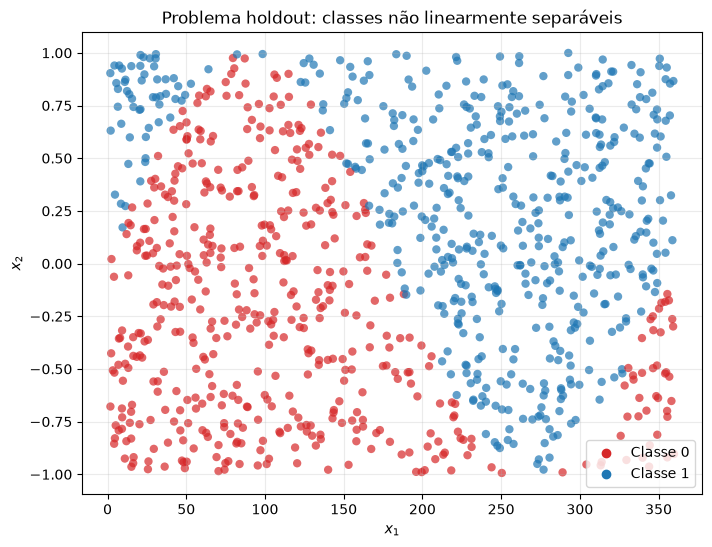

Treino: 700 exemplos | Teste: 300 exemplos
Escala usada na normalização (máximo absoluto no treino): [359.78894128   0.994249  ]


In [6]:
X_holdout, y_holdout = carregar_dados('dataHoldout20262.txt')
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_holdout[:, 0], X_holdout[:, 1], c=CORES[y_holdout], alpha=0.7, edgecolors='none')
ax.scatter([], [], color='tab:red', label='Classe 0')
ax.scatter([], [], color='tab:blue', label='Classe 1')
ax.set(title='Problema holdout: classes não linearmente separáveis', xlabel='$x_1$', ylabel='$x_2$')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

gerador_holdout = np.random.default_rng(IDENTIFICADOR_EQUIPE)
indices = gerador_holdout.permutation(X_holdout.shape[0])
limite_treino = int(0.7 * X_holdout.shape[0])
indices_treino, indices_teste = indices[:limite_treino], indices[limite_treino:]
X_treino, y_treino = X_holdout[indices_treino], y_holdout[indices_treino]
X_teste, y_teste = X_holdout[indices_teste], y_holdout[indices_teste]
X_treino_norm, escala_holdout = normalizar(X_treino)
X_teste_norm, _ = normalizar(X_teste, escala_holdout)
print(f'Treino: {X_treino.shape[0]} exemplos | Teste: {X_teste.shape[0]} exemplos')
print('Escala usada na normalização (máximo absoluto no treino):', escala_holdout)

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

resultado_holdout = treinar_perceptron(
    X_treino_norm, y_treino, taxa_aprendizado=0.1, intervalo=(-0.5, 0.5),
    max_epocas=100, embaralhar=True, gerador=gerador_holdout, parar_na_convergencia=False
)
pesos_holdout = pesos_escala_original(resultado_holdout['pesos'], escala_holdout)
print('Vetor inicial de pesos [bias, w1, w2]:', resultado_holdout['pesos_iniciais'])
print('Vetor final de pesos (dados normalizados):', resultado_holdout['pesos'])
print(f'Ajustes em 100 épocas: {resultado_holdout["ajustes"]}')
print('Erros nas últimas 5 épocas:', resultado_holdout['historico_erros'][-5:])

y_previsto_treino = prever(X_treino_norm, resultado_holdout['pesos'])
y_previsto_teste = prever(X_teste_norm, resultado_holdout['pesos'])

matriz_confusao = confusion_matrix(y_teste, y_previsto_teste, labels=[0, 1])
print('\nMatriz de confusão do conjunto de teste:')
display(pd.DataFrame(matriz_confusao, index=['Real 0', 'Real 1'],
                     columns=['Previsto 0', 'Previsto 1']))

def metricas(y_real, y_previsto):
    return {
        'Acurácia': accuracy_score(y_real, y_previsto),
        'Precisão': precision_score(y_real, y_previsto, zero_division=0),
        'Revocação': recall_score(y_real, y_previsto, zero_division=0),
        'F1-Score': f1_score(y_real, y_previsto, zero_division=0),
    }

tabela_metricas = pd.DataFrame({
    'Treinamento': metricas(y_treino, y_previsto_treino),
    'Teste': metricas(y_teste, y_previsto_teste),
})
display(tabela_metricas.style.format('{:.2%}'))

Vetor inicial de pesos [bias, w1, w2]: [-0.10152156 -0.00099069 -0.3011742 ]
Vetor final de pesos (dados normalizados): [-0.20152156  0.45839655  0.03735662]
Ajustes em 100 épocas: 16757
Erros nas últimas 5 épocas: [162, 165, 180, 160, 177]

Matriz de confusão do conjunto de teste:


,Previsto 0,Previsto 1
Real 0,120,24
Real 1,21,135


,Treinamento,Teste
Acurácia,83.43%,85.00%
Precisão,80.41%,84.91%
Revocação,88.64%,86.54%
F1-Score,84.32%,85.71%


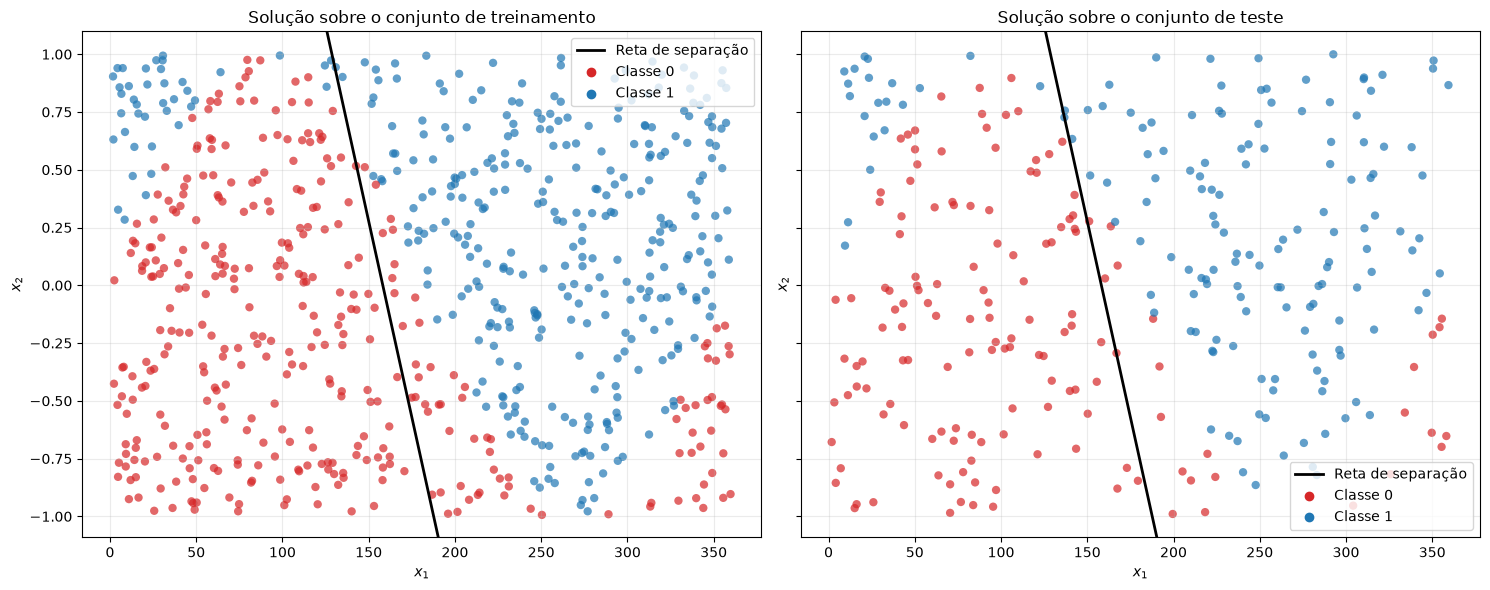

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
plotar_dados_e_reta(X_treino, y_treino, pesos_holdout, eixos[0],
                    'Solução sobre o conjunto de treinamento')
plotar_dados_e_reta(X_teste, y_teste, pesos_holdout, eixos[1],
                    'Solução sobre o conjunto de teste')
plt.tight_layout()
plt.show()

### Respostas

**1. Matriz de confusão (teste).** Das 300 amostras de teste, 120 da classe 0 e 135 da classe 1 foram classificadas corretamente; houve 24 falsos positivos (classe 0 prevista como 1) e 21 falsos negativos (classe 1 prevista como 0).

| | Previsto 0 | Previsto 1 |
|---|---|---|
| **Real 0** | 120 | 24 |
| **Real 1** | 21 | 135 |

**2. Acurácia.** No conjunto de treinamento, a acurácia foi de **83,43%** (584 de 700 exemplos). No conjunto de teste, foi de **85,00%** (255 de 300).

**3. Precisão, revocação e F-Score** (classe positiva = 1):

| Métrica | Treinamento | Teste |
|---|---|---|
| Precisão | 80,41% | 84,91% |
| Revocação | 88,64% | 86,54% |
| F1-Score | 84,32% | 85,71% |

**4. Qualidade da solução.** Para uma única reta num problema não linearmente separável, o resultado é razoável: cerca de 85% de acerto no teste, com precisão e revocação equilibradas (o neurônio não favorece muito nenhuma das classes). As métricas de teste ficaram próximas às de treinamento, então a reta generaliza de forma consistente e não há sinal de sobreajuste. Por outro lado, os gráficos mostram que nenhuma reta separa todos os exemplos: há exemplos da classe 1 no canto superior esquerdo, entre os da classe 0, e da classe 0 no canto inferior direito, entre os da classe 1. É nessas regiões que se concentram os cerca de 15% de erros. Outro limite é que o treinamento não converge: na última época ainda houve entre 160 e 180 ajustes, e os pesos finais são apenas os do fim da 100ª época, não necessariamente os melhores já vistos. Para melhorar seria preciso um modelo não linear (por exemplo, um Perceptron multicamadas) ou, mantendo o neurônio, guardar os melhores pesos durante o treinamento (algoritmo *pocket*).